# PDAN8412 Part 2: Bestseller Classification with Logistic Regression from Scratch
**Student:** Boitumelo Malinga  
**Student number:** ST10107491

I developed a binary classifier for a book press using the 27,027-record CORGIS Publishers dataset. Spark was used for loading, cleaning, exploratory analysis and modelling-data preparation. Logistic regression was then implemented from scratch with NumPy, as permitted by the brief.

## Objectives
I evaluated data quality and suitability, planned the analysis, conducted Spark EDA, controlled target leakage, trained baseline and improved from-scratch models, selected the final model on validation F1-score and evaluated it once on unseen test data.

## Imports

In [1]:
from pathlib import Path
import json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, mannwhitneyu
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve
warnings.filterwarnings('ignore')
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
NAVY='#15324B'; BLUE='#2F75B5'; GREEN='#2E8B57'; RED='#C94C4C'
def show_table(df, caption, precision=4, hide_index=False):
    s=(df.style.set_caption(caption).format(precision=precision, thousands=',').set_table_styles([
      {'selector':'caption','props':[('caption-side','top'),('background-color',NAVY),('color','white'),('font-weight','bold'),('padding','10px')]},
      {'selector':'th','props':[('background-color',BLUE),('color','white'),('text-align','center')]},
      {'selector':'td','props':[('text-align','center'),('border','1px solid #ccd6df'),('padding','6px')]},
      {'selector':'tbody tr:nth-child(even)','props':[('background-color','#eef5fa')]}]))
    if hide_index: s=s.hide(axis='index')
    display(s)
print('Libraries imported successfully.')

Libraries imported successfully.


# 1. Dataset Suitability
The CORGIS Publishers dataset contains Amazon e-book sales information across genres and publisher types. It exceeds the required 10,000 records and contains a binary-classification target source (sales rank), explanatory metadata and early reader-response measures. It is cross-sectional rather than time-oriented, so the model estimates membership of a high-ranking group and does not forecast a future sales date.

## Dataset Source and Provenance

In [2]:
source=pd.DataFrame({'Item':['Dataset','Publisher','Direct link','Downloaded records','Source description','Analysis limitation'],'Value':['Publishers CSV','CORGIS Dataset Project','https://corgis-edu.github.io/corgis/csv/publishers/',27027,'Amazon e-book sales, rankings, genres and publisher information','Cross-sectional data; no title, author or observation date']}); show_table(source,'Table 1: Dataset Source and Provenance',hide_index=True)

Item,Value
Dataset,Publishers CSV
Publisher,CORGIS Dataset Project
Direct link,https://corgis-edu.github.io/corgis/csv/publishers/
Downloaded records,"27,027"
Source description,"Amazon e-book sales, rankings, genres and publisher information"
Analysis limitation,"Cross-sectional data; no title, author or observation date"


## Analysis Plan

In [3]:
plan=pd.DataFrame({'Stage':['Quality','Target','Spark EDA','Features','Training','Evaluation'], 'Action':['Inspect schema, nulls, duplicates and ranges in Spark.','Define the best-ranked quartile as bestseller.','Analyse distributions and grouped patterns with Spark.','Exclude identifiers and realised sales outcomes.','Implement sigmoid, loss and gradient descent with NumPy.','Select on validation F1 and evaluate once on test data.']})
show_table(plan,'Table 2: Analysis Plan',hide_index=True)

Stage,Action
Quality,"Inspect schema, nulls, duplicates and ranges in Spark."
Target,Define the best-ranked quartile as bestseller.
Spark EDA,Analyse distributions and grouped patterns with Spark.
Features,Exclude identifiers and realised sales outcomes.
Training,"Implement sigmoid, loss and gradient descent with NumPy."
Evaluation,Select on validation F1 and evaluate once on test data.


## Starting Spark

In [4]:
spark=(SparkSession.builder.appName('PDAN8412_Part2_Bestseller').master('local[*]').config('spark.sql.shuffle.partitions','8').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('Spark version:',spark.version)

26/10/19 10:16:58 WARN Utils: Your hostname, Boitumelos-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.78.8.113 instead (on interface en0)
26/10/19 10:16:58 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/19 10:16:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 3.5.9


## Loading the 27,027-Record Dataset

In [5]:
paths=[Path('publishers.csv'),Path('data/publishers.csv'),Path.home()/'Downloads'/'publishers.csv',Path.home()/'Documents'/'PDAN8412_Part2'/'publishers.csv']
DATA_PATH=next((p for p in paths if p.exists()),None)
if DATA_PATH is None: raise FileNotFoundError('Place publishers.csv beside this notebook.')
spark_data=spark.read.option('header',True).option('inferSchema',True).csv(str(DATA_PATH))
print(f'Rows: {spark_data.count():,}; columns: {len(spark_data.columns)}')

Rows: 27,027; columns: 13


## Dataset Preview

In [6]:
show_table(spark_data.limit(5).toPandas(),'Table 3: Dataset Preview',precision=2,hide_index=True)

genre,sold by,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,publisher.name,publisher.type,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
genre fiction,HarperCollins Publishers,"6,832.00","6,832.00","34,160.00","20,496.00","7,000",Katherine Tegen Books,big five,4.57,4.88,1,"9,604"
genre fiction,HarperCollins Publishers,"2,487.50","2,487.50","12,437.50","7,462.50","6,250",HarperCollins e-books,big five,4.47,1.99,2,450
genre fiction,"Amazon Digital Services, Inc.","9,559.00","9,559.00","47,795.00","28,677.00","5,500",(Small or Medium Publisher),small/medium,4.16,8.69,3,30
fiction,Hachette Book Group,"8,250.00","8,250.00","41,250.00","24,750.00","5,500","Little, Brown and Company",big five,3.84,7.50,3,"3,747"
genre fiction,Penguin Group (USA) LLC,"7,590.50","7,590.50","37,952.50","22,771.50","4,750",Dutton Children's,big five,4.75,7.99,4,"9,174"


## Schema

In [7]:
schema=pd.DataFrame([(f.name,str(f.dataType),f.nullable) for f in spark_data.schema.fields],columns=['Column','Type','Nullable']); show_table(schema,'Table 4: Spark Schema',hide_index=True)

Column,Type,Nullable
genre,StringType(),True
sold by,StringType(),True
daily average.amazon revenue,DoubleType(),True
daily average.author revenue,DoubleType(),True
daily average.gross sales,DoubleType(),True
daily average.publisher revenue,DoubleType(),True
daily average.units sold,IntegerType(),True
publisher.name,StringType(),True
publisher.type,StringType(),True
statistics.average rating,DoubleType(),True


## Missing Values

In [8]:
missing = spark_data.select([
    F.sum(
        F.col(f"`{column}`").isNull().cast("int")
    ).alias(column)
    for column in spark_data.columns
]).toPandas().T.reset_index()

missing.columns = ["Column", "Missing"]

show_table(
    missing,
    "Table 5: Missing Values",
    hide_index=True
)

Column,Missing
genre,0
sold by,0
daily average.amazon revenue,0
daily average.author revenue,0
daily average.gross sales,0
daily average.publisher revenue,0
daily average.units sold,0
publisher.name,0
publisher.type,0
statistics.average rating,0


## Duplicate Check

In [9]:
quality=pd.DataFrame({'Measure':['Rows','Columns','Complete duplicates'],'Value':[spark_data.count(),len(spark_data.columns),spark_data.count()-spark_data.dropDuplicates().count()]}); show_table(quality,'Table 6: Dataset Quality Summary',hide_index=True)

Measure,Value
Rows,"27,027"
Columns,13
Complete duplicates,0


The dataset contained 27,027 complete records and no complete duplicates. Spark identified no null values. Extreme values were retained for EDA because they represented observed rankings, prices and sales outcomes rather than missing data.

## Cleaning and Renaming
I replaced the long source headings with concise names so the Spark queries, model code and report outputs remained readable.

In [10]:
rename={'genre':'genre','sold by':'seller','daily average.amazon revenue':'amazon_revenue_daily','daily average.author revenue':'author_revenue_daily','daily average.gross sales':'gross_sales_daily','daily average.publisher revenue':'publisher_revenue_daily','daily average.units sold':'units_sold_daily','publisher.name':'publisher_name','publisher.type':'publisher_type','statistics.average rating':'average_rating','statistics.sale price':'sale_price','statistics.sales rank':'sales_rank','statistics.total reviews':'total_reviews'}
clean=spark_data
for old,new in rename.items(): clean=clean.withColumnRenamed(old,new)
clean=clean.dropDuplicates()
print('Clean rows:',clean.count())

Clean rows: 27027


## Target Definition

In [11]:
rank_cutoff=clean.approxQuantile('sales_rank',[0.25],0.0)[0]
clean=clean.withColumn('bestseller',F.when(F.col('sales_rank')<=rank_cutoff,1).otherwise(0))
target=clean.groupBy('bestseller').count().orderBy('bestseller').toPandas(); target['percentage']=target['count']/target['count'].sum()*100
show_table(target,'Table 7: Bestseller Class Distribution',precision=2,hide_index=True)

bestseller,count,percentage
0,"20,270",75.00
1,"6,757",25.00


I defined a bestseller as a title in the best-ranked quarter of this dataset. Lower sales ranks represented stronger performance. This operational label was transparent and balanced enough for classification, but it was not presented as a universal publishing-industry definition.

## Class Distribution Graph

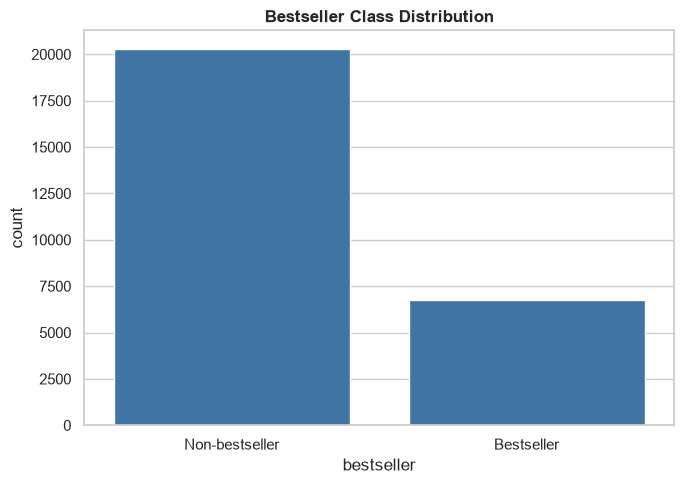

In [12]:
plt.figure(figsize=(7,5)); sns.barplot(data=target,x='bestseller',y='count',color=BLUE); plt.xticks([0,1],['Non-bestseller','Bestseller']); plt.title('Bestseller Class Distribution',fontweight='bold'); plt.tight_layout(); plt.show()

## Spark Descriptive Statistics

In [13]:
nums=['average_rating','sale_price','sales_rank','total_reviews','units_sold_daily']; desc=clean.select(nums).summary().toPandas(); show_table(desc,'Table 8: Numerical Descriptive Statistics',precision=2,hide_index=True)

26/10/19 10:17:07 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


summary,average_rating,sale_price,sales_rank,total_reviews,units_sold_daily
count,27027,27027,27027,27027,27027
mean,4.159786509786555,6.7774876974873735,38200.142857142855,136.0993450993451,29.614052614052614
stddev,0.9958153966260691,6.368486133292314,29056.493295891076,468.95299876888856,157.73949970205695
min,0.0,0.01,1,0,1
25%,4.08,2.99,11985,12,4
50%,4.4,5.12,32803,37,9
75%,4.64,9.99,61135,111,14
max,5.0,141.52,99974,23362,7000


The descriptive statistics showed substantial skewness in reviews and units sold. These fields were not assumed to follow a normal distribution, which informed the use of medians, robust visual summaries and a non-parametric feature test.

## Sales-Rank Distribution

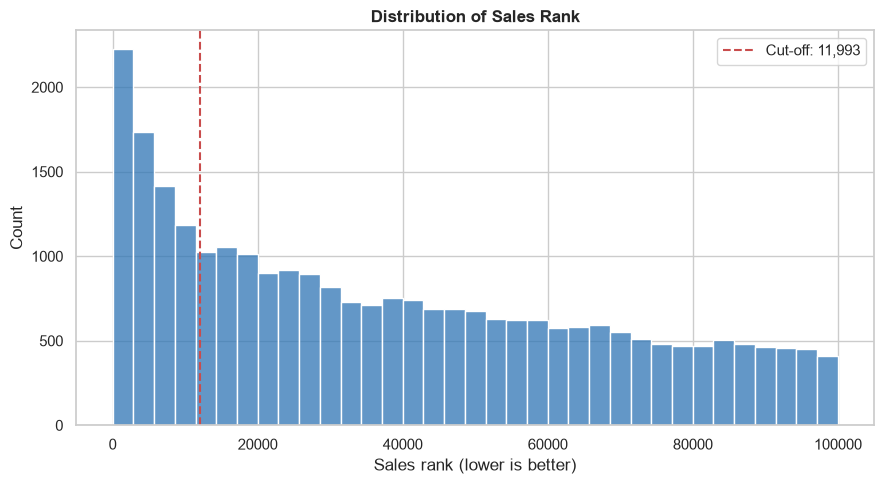

In [14]:
rank_plot=clean.select('sales_rank').toPandas(); plt.figure(figsize=(9,5)); sns.histplot(rank_plot['sales_rank'],bins=35,color=BLUE); plt.axvline(rank_cutoff,color=RED,linestyle='--',label=f'Cut-off: {rank_cutoff:,.0f}'); plt.xlabel('Sales rank (lower is better)'); plt.title('Distribution of Sales Rank',fontweight='bold'); plt.legend(); plt.tight_layout(); plt.show()

The cut-off divided the best-ranked quarter from the remaining observations. Sales rank was used only to construct the target and was not included as a predictor.

## Average-Rating Distribution

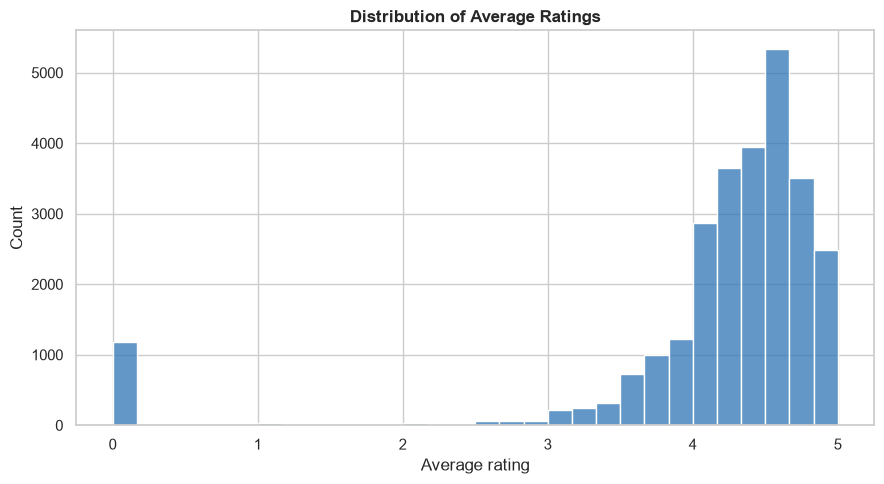

In [15]:
rating_plot=clean.select('average_rating').toPandas(); plt.figure(figsize=(9,5)); sns.histplot(rating_plot['average_rating'],bins=30,color=BLUE); plt.xlabel('Average rating'); plt.title('Distribution of Average Ratings',fontweight='bold'); plt.tight_layout(); plt.show()

The rating distribution included a concentration of highly rated books and a smaller group with zero or low ratings. Standardisation prevented its scale from dominating gradient updates.

## Sale-Price Distribution

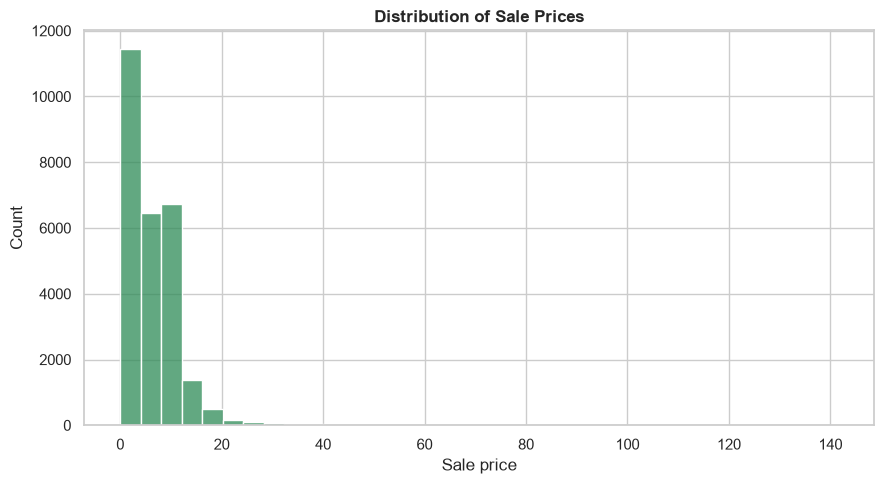

In [16]:
price_plot=clean.select('sale_price').toPandas(); plt.figure(figsize=(9,5)); sns.histplot(price_plot['sale_price'],bins=35,color=GREEN); plt.xlabel('Sale price'); plt.title('Distribution of Sale Prices',fontweight='bold'); plt.tight_layout(); plt.show()

Sale price was right-skewed and contained a small number of expensive books. It remained a useful commercial characteristic but was interpreted together with the other predictors.

## Total-Reviews Distribution

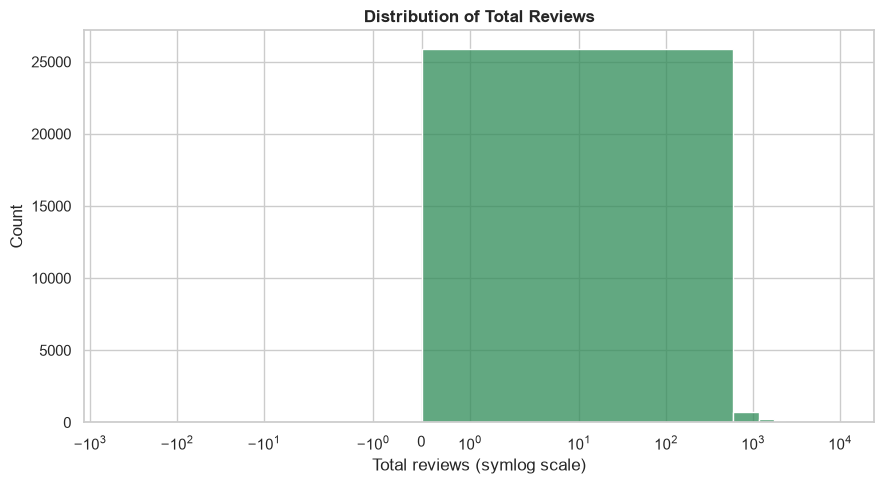

In [17]:
review_plot=clean.select('total_reviews').toPandas(); plt.figure(figsize=(9,5)); sns.histplot(review_plot['total_reviews'],bins=40,color=GREEN); plt.xscale('symlog'); plt.xlabel('Total reviews (symlog scale)'); plt.title('Distribution of Total Reviews',fontweight='bold'); plt.tight_layout(); plt.show()

Review counts were strongly right-skewed. A transformed display was used for readability, while standardisation was fitted on the training data for modelling.

## Units-Sold Distribution

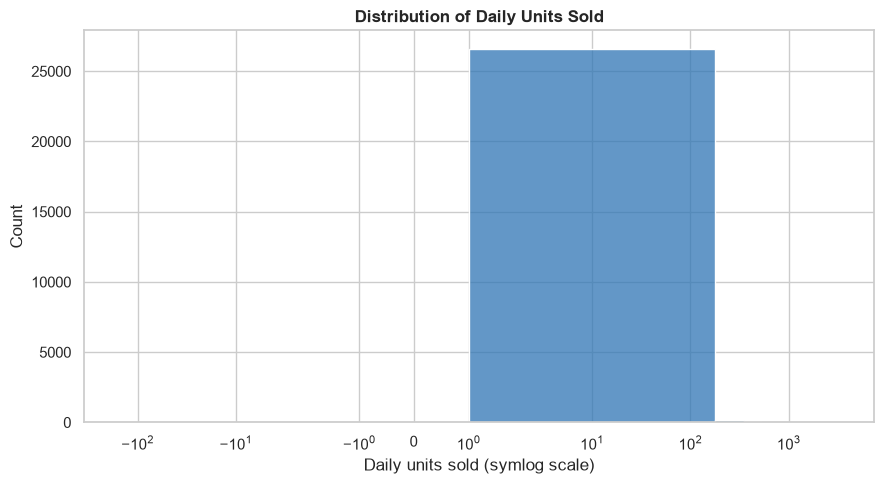

In [18]:
units_plot=clean.select('units_sold_daily').toPandas(); plt.figure(figsize=(9,5)); sns.histplot(units_plot['units_sold_daily'],bins=40,color=BLUE); plt.xscale('symlog'); plt.xlabel('Daily units sold (symlog scale)'); plt.title('Distribution of Daily Units Sold',fontweight='bold'); plt.tight_layout(); plt.show()

Daily units sold directly reflected realised performance and was excluded from training to prevent the model from learning the answer from another sales outcome.

## Numerical Predictors by Bestseller Class

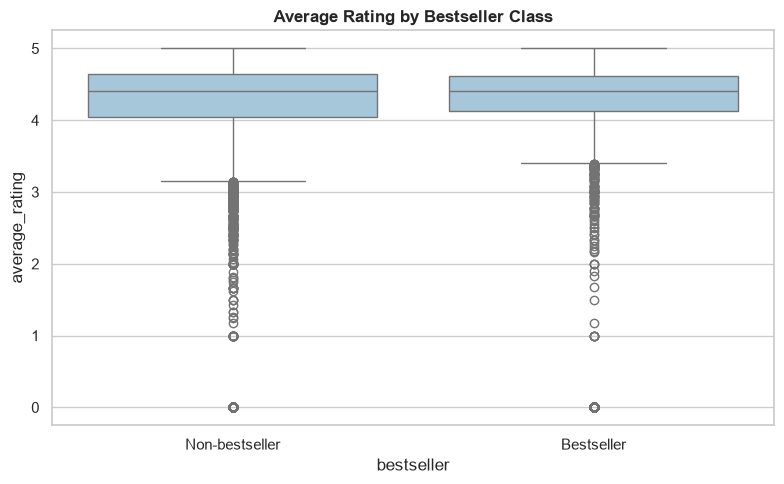

In [19]:
class_numeric=clean.select('bestseller','average_rating','sale_price','total_reviews').toPandas(); plt.figure(figsize=(8,5)); sns.boxplot(data=class_numeric,x='bestseller',y='average_rating',color='#9ecae1'); plt.xticks([0,1],['Non-bestseller','Bestseller']); plt.title('Average Rating by Bestseller Class',fontweight='bold'); plt.tight_layout(); plt.show()

The rating distributions overlapped, indicating that rating alone could not determine bestseller status.

## Sale Price by Bestseller Class

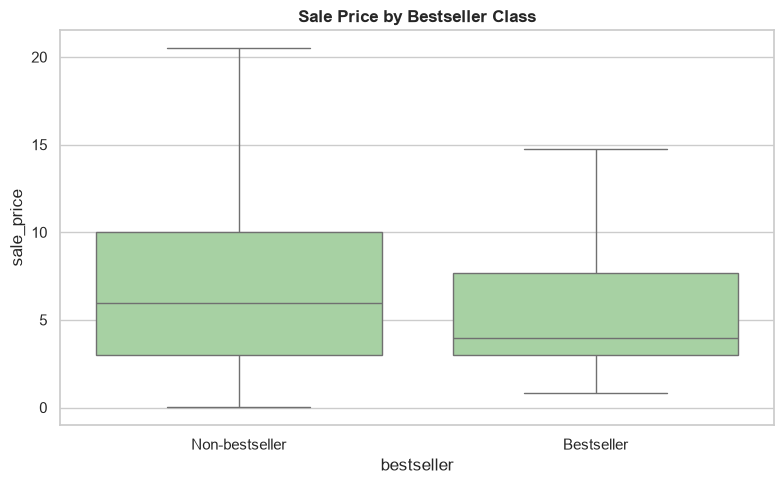

In [20]:
plt.figure(figsize=(8,5)); sns.boxplot(data=class_numeric,x='bestseller',y='sale_price',color='#a1d99b',showfliers=False); plt.xticks([0,1],['Non-bestseller','Bestseller']); plt.title('Sale Price by Bestseller Class',fontweight='bold'); plt.tight_layout(); plt.show()

The class comparison showed whether pricing patterns differed after reducing the visual effect of extreme outliers.

## Total Reviews by Bestseller Class

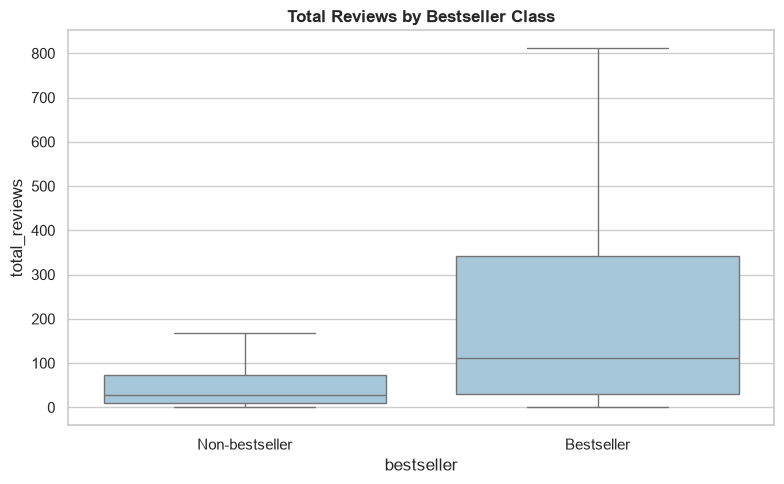

In [21]:
plt.figure(figsize=(8,5)); sns.boxplot(data=class_numeric,x='bestseller',y='total_reviews',color='#9ecae1',showfliers=False); plt.xticks([0,1],['Non-bestseller','Bestseller']); plt.title('Total Reviews by Bestseller Class',fontweight='bold'); plt.tight_layout(); plt.show()

The review-count difference supported its use as an early market-response predictor, while also confirming that this was not a pre-publication model.

## Bestseller Rate by Genre

In [22]:
genre=clean.groupBy('genre').agg(F.count('*').alias('books'),F.sum('bestseller').alias('bestsellers'),(F.avg('bestseller')*100).alias('bestseller_rate')).orderBy(F.desc('bestseller_rate')).toPandas(); show_table(genre,'Table 8: Bestseller Performance by Genre',precision=2,hide_index=True)

genre,books,bestsellers,bestseller_rate
fiction,733,396,54.02
genre fiction,"8,903","4,254",47.78
nonfiction,"14,161","1,822",12.87
children,"2,541",271,10.67
comics,568,14,2.46
foreign language,121,0,0.00


## Genre Graph

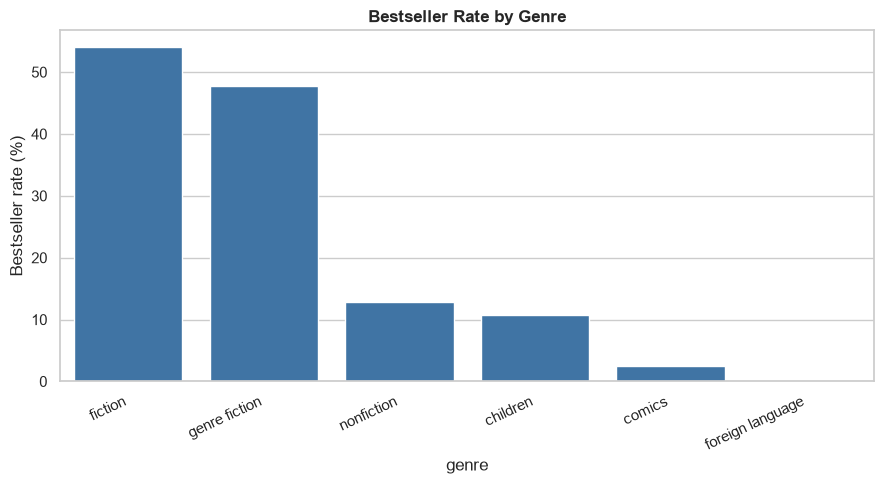

In [23]:
plt.figure(figsize=(9,5)); sns.barplot(data=genre,x='genre',y='bestseller_rate',color=BLUE); plt.xticks(rotation=25,ha='right'); plt.ylabel('Bestseller rate (%)'); plt.title('Bestseller Rate by Genre',fontweight='bold'); plt.tight_layout(); plt.show()

## Bestseller Rate by Publisher Type

In [24]:
ptype=clean.groupBy('publisher_type').agg(F.count('*').alias('books'),F.sum('bestseller').alias('bestsellers'),(F.avg('bestseller')*100).alias('bestseller_rate')).orderBy(F.desc('bestseller_rate')).toPandas(); show_table(ptype,'Table 9: Bestseller Performance by Publisher Type',precision=2,hide_index=True)

publisher_type,books,bestsellers,bestseller_rate
amazon,423,272,64.30
indie,"5,946","2,041",34.33
big five,"7,309","2,292",31.36
single author,"3,608",824,22.84
small/medium,"9,741","1,328",13.63


## Publisher-Type Graph

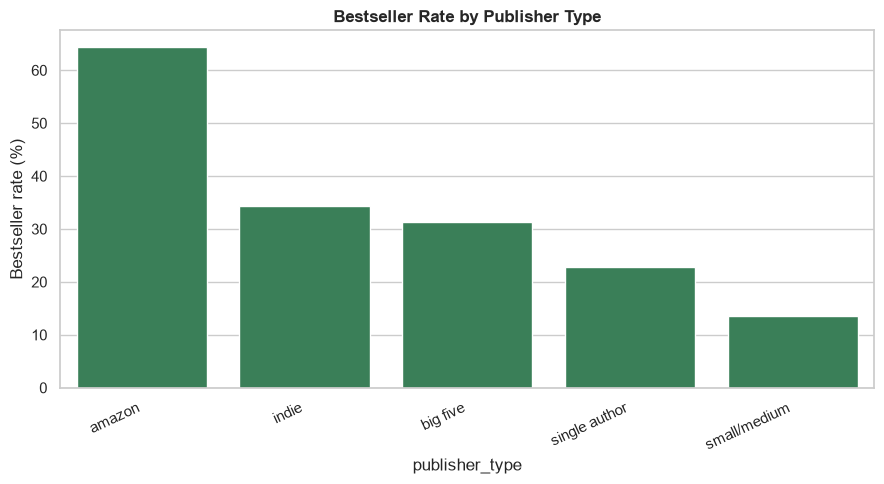

In [25]:
plt.figure(figsize=(9,5)); sns.barplot(data=ptype,x='publisher_type',y='bestseller_rate',color=GREEN); plt.xticks(rotation=25,ha='right'); plt.ylabel('Bestseller rate (%)'); plt.title('Bestseller Rate by Publisher Type',fontweight='bold'); plt.tight_layout(); plt.show()

Publisher type captured broad structural differences, but the observed rates were associations rather than proof that a publishing model caused stronger sales.

## Bestseller Rate by Seller

In [26]:
seller=clean.groupBy('seller').agg(F.count('*').alias('books'),F.sum('bestseller').alias('bestsellers'),(F.avg('bestseller')*100).alias('bestseller_rate')).orderBy(F.desc('books')).toPandas(); show_table(seller,'Table 11: Bestseller Performance by Seller',precision=2,hide_index=True)

seller,books,bestsellers,bestseller_rate
"Amazon Digital Services, Inc.","19,548","4,460",22.82
Random House LLC,"1,964",520,26.48
Penguin Group (USA) LLC,"1,411",480,34.02
HarperCollins Publishers,"1,244",395,31.75
Simon and Schuster Digital Sales Inc,"1,108",297,26.81
Macmillan,777,247,31.79
Hachette Book Group,608,286,47.04
DC Comics,125,5,4.00
HarperCollins Publishing,99,33,33.33
HarperCollins Christian Publishing,96,33,34.38


## Seller Graph

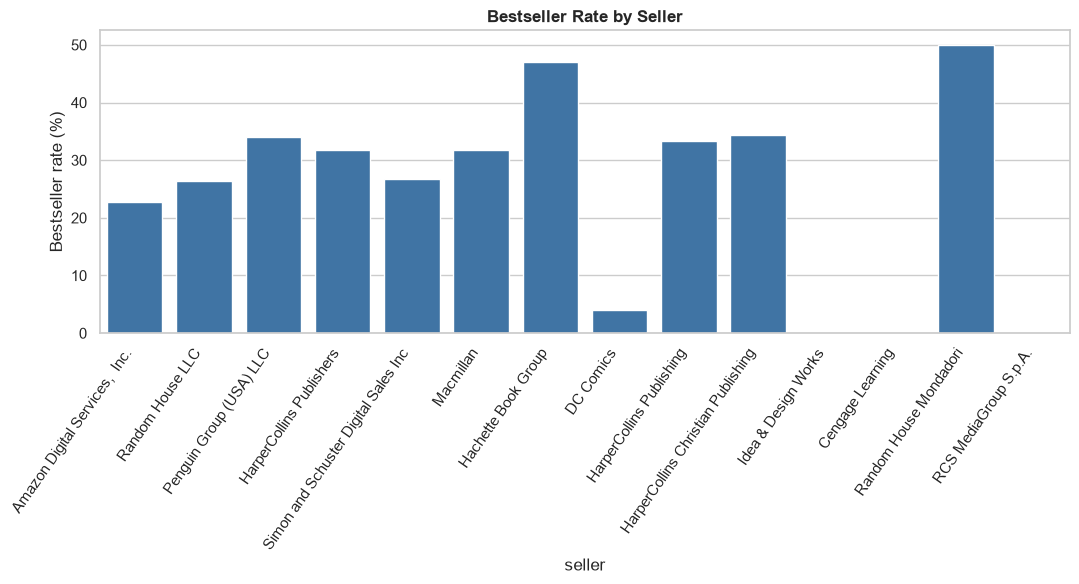

In [27]:
plt.figure(figsize=(11,6)); sns.barplot(data=seller,x='seller',y='bestseller_rate',color=BLUE); plt.xticks(rotation=55,ha='right'); plt.ylabel('Bestseller rate (%)'); plt.title('Bestseller Rate by Seller',fontweight='bold'); plt.tight_layout(); plt.show()

Seller groups differed in size and observed performance. The smallest groups were interpreted cautiously because their percentages were based on fewer books.

## Spark Correlations with the Target

In [28]:
corr=pd.DataFrame({'Feature':['average_rating','sale_price','total_reviews'],'Correlation':[clean.stat.corr(x,'bestseller') for x in ['average_rating','sale_price','total_reviews']]}); show_table(corr.set_index('Feature'),'Table 10: Predictor Correlations with Bestseller Status',precision=4)

,Correlation
Feature,
average_rating,0.0152
sale_price,-0.1412
total_reviews,0.2619


## Numerical Correlation Heatmap

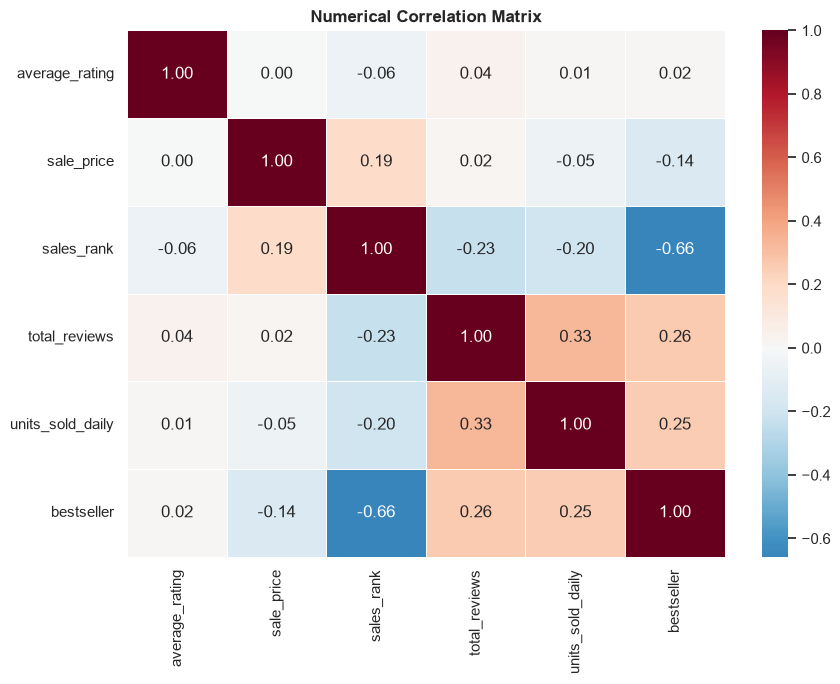

In [29]:
corr_pd=clean.select('average_rating','sale_price','sales_rank','total_reviews','units_sold_daily','bestseller').toPandas().corr(); plt.figure(figsize=(9,7)); sns.heatmap(corr_pd,annot=True,fmt='.2f',cmap='RdBu_r',center=0,linewidths=.5); plt.title('Numerical Correlation Matrix',fontweight='bold'); plt.tight_layout(); plt.show()

The heatmap made the leakage risk visible: sales rank and units sold represented realised performance. Only the leakage-safe rating, price and review measures continued into the model.

# 2. Feature Selection and Leakage Control
I retained average rating, sale price, total reviews, genre, seller and publisher type. Sales rank created the target and was excluded. Units sold and all revenue fields were excluded because they described realised sales performance. Detailed publisher name was excluded because its 309 categories would create a sparse, unstable design. Ratings and reviews make this an early-market screening model rather than a pre-publication model.

In [30]:
roles=pd.DataFrame({'Role':['Selected','Target source','Leakage exclusions','High-cardinality exclusion'],'Columns':['average rating, sale price, total reviews, genre, sold by, publisher type','sales rank','units sold and all revenue fields','publisher name']}); show_table(roles,'Table 11: Feature Decisions',hide_index=True)

Role,Columns
Selected,"average rating, sale price, total reviews, genre, sold by, publisher type"
Target source,sales rank
Leakage exclusions,units sold and all revenue fields
High-cardinality exclusion,publisher name


## Spark Modelling Extract

In [31]:
selected=['average_rating','sale_price','total_reviews','genre','seller','publisher_type','bestseller']; model_pd=clean.select(selected).toPandas(); print(model_pd.shape)

(27027, 7)


## Numerical Feature Tests

In [32]:
num_test=[]
for feature in ['average_rating','sale_price','total_reviews']:
    a=model_pd.loc[model_pd.bestseller==0,feature]; b=model_pd.loc[model_pd.bestseller==1,feature]
    stat,p=mannwhitneyu(a,b,alternative='two-sided')
    num_test.append({'Feature':feature,'Non-bestseller median':a.median(),'Bestseller median':b.median(),'Mann-Whitney U':stat,'p-value':p})
num_tests=pd.DataFrame(num_test).set_index('Feature'); show_table(num_tests,'Table 13: Numerical Feature Tests',precision=4)

,Non-bestseller median,Bestseller median,Mann-Whitney U,p-value
Feature,,,,
average_rating,4.4000,4.4100,"68,267,980.5000",0.6997
sale_price,5.9800,3.9900,"82,234,876.0000",0.0000
total_reviews,28.0000,111.0000,"39,707,595.5000",0.0000


The Mann–Whitney tests assessed whether the distributions differed without assuming normality. Statistical significance was used as supporting evidence and not as an automatic feature-deletion rule.

## Categorical Feature Tests

In [33]:
cat_test=[]
for feature in ['genre','seller','publisher_type']:
    tab=pd.crosstab(model_pd[feature],model_pd.bestseller); stat,p,dof,_=chi2_contingency(tab); n=tab.values.sum(); v=np.sqrt(stat/(n*(min(tab.shape)-1)))
    cat_test.append({'Feature':feature,'Chi-square':stat,'Degrees of freedom':dof,'p-value':p,"Cramer's V":v})
cat_tests=pd.DataFrame(cat_test).set_index('Feature'); show_table(cat_tests,'Table 14: Categorical Feature Tests',precision=4)

,Chi-square,Degrees of freedom,p-value,Cramer's V
Feature,,,,
genre,"4,378.1740",5,0.0000,0.4025
seller,375.2427,13,0.0000,0.1178
publisher_type,"1,462.0913",4,0.0000,0.2326


Chi-square tests assessed association with bestseller status, while Cramér's V described effect size. Business availability, leakage risk and interpretability were considered together with the statistical results.

## Train, Validation and Test Split

In [34]:
X=model_pd.drop(columns='bestseller'); y=model_pd['bestseller']
X_train,X_tmp,y_train,y_tmp=train_test_split(X,y,test_size=.30,stratify=y,random_state=RANDOM_STATE)
X_val,X_test,y_val,y_test=train_test_split(X_tmp,y_tmp,test_size=.50,stratify=y_tmp,random_state=RANDOM_STATE)
splits=pd.DataFrame({'Set':['Training','Validation','Test'],'Rows':[len(y_train),len(y_val),len(y_test)],'Bestsellers':[y_train.sum(),y_val.sum(),y_test.sum()]}); show_table(splits,'Table 12: Data Split',hide_index=True)

Set,Rows,Bestsellers
Training,"18,918","4,730"
Validation,"4,054","1,013"
Test,"4,055","1,014"


## Preprocessing

In [35]:
numeric=['average_rating','sale_price','total_reviews']; categorical=['genre','seller','publisher_type']
pre=ColumnTransformer([('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=False))]),categorical)])
Xt=pre.fit_transform(X_train); Xv=pre.transform(X_val); Xte=pre.transform(X_test); names=pre.get_feature_names_out(); print(Xt.shape,Xv.shape,Xte.shape)

(18918, 25) (4054, 25) (4055, 25)


# 3. Logistic Regression from Scratch
The linear score was converted to probability with the sigmoid function. Binary cross-entropy measured error, and batch gradient descent updated weights and the intercept. The improved model added L2 regularisation and class-weighted loss.

In [36]:
class LogisticRegressionFromScratch:
    def __init__(self,lr=.05,iterations=800,l2=0,class_weight=None): self.lr=lr; self.iterations=iterations; self.l2=l2; self.class_weight=class_weight
    @staticmethod
    def sigmoid(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
    def fit(self,X,y):
        X=np.asarray(X,float); y=np.asarray(y,float); n,p=X.shape; self.weights=np.zeros(p); self.intercept=0.; self.loss=[]
        sw=np.ones(n) if self.class_weight is None else np.where(y==1,self.class_weight[1],self.class_weight[0])
        for i in range(self.iterations):
            prob=self.sigmoid(X@self.weights+self.intercept); err=(prob-y)*sw
            self.weights-=self.lr*((X.T@err)/n+self.l2*self.weights/n); self.intercept-=self.lr*err.mean()
            if i%25==0: self.loss.append(-np.mean(sw*(y*np.log(prob+1e-12)+(1-y)*np.log(1-prob+1e-12)))+self.l2*np.sum(self.weights**2)/(2*n))
        return self
    def predict_proba(self,X): return self.sigmoid(np.asarray(X)@self.weights+self.intercept)
def metrics(y,p,t,name):
    q=(p>=t).astype(int); return {'Model':name,'Threshold':t,'Accuracy':accuracy_score(y,q),'Precision':precision_score(y,q),'Recall':recall_score(y,q),'F1-score':f1_score(y,q),'ROC-AUC':roc_auc_score(y,p),'Average precision':average_precision_score(y,p)}

## Baseline Model Configuration

In [37]:
baseline_config=pd.DataFrame({'Parameter':['Learning rate','Iterations','L2 strength','Class weighting','Initial threshold'],'Value':[0.05,800,0.0,'None',0.50]}); show_table(baseline_config,'Table 17: Baseline Model Configuration',hide_index=True)

Parameter,Value
Learning rate,0.0500
Iterations,800
L2 strength,0.0000
Class weighting,None
Initial threshold,0.5000


## Improved Model Configuration

In [38]:
ratio=(y_train==0).sum()/(y_train==1).sum(); improved_config=pd.DataFrame({'Parameter':['Learning rate','Iterations','L2 strength','Positive-class weight','Threshold rule'],'Value':[0.03,1200,1.0,ratio,'Highest validation F1']}); show_table(improved_config,'Table 18: Improved Model Configuration',precision=4,hide_index=True)

Parameter,Value
Learning rate,0.0300
Iterations,"1,200"
L2 strength,1.0000
Positive-class weight,2.9996
Threshold rule,Highest validation F1


## Training the Two Models

In [39]:
baseline=LogisticRegressionFromScratch().fit(Xt,y_train)
improved=LogisticRegressionFromScratch(lr=.03,iterations=1200,l2=1,class_weight={0:1,1:ratio}).fit(Xt,y_train)
bp=baseline.predict_proba(Xv); ip=improved.predict_proba(Xv)
thresholds=np.arange(.2,.81,.01); threshold_f1=[f1_score(y_val,ip>=t) for t in thresholds]
it=round(float(thresholds[np.argmax(threshold_f1)]),2)
comparison=pd.DataFrame([metrics(y_val,bp,.5,'Baseline'),metrics(y_val,ip,it,'Improved')]).set_index('Model')
print('Both models trained successfully.')

Both models trained successfully.


## Baseline Training Loss

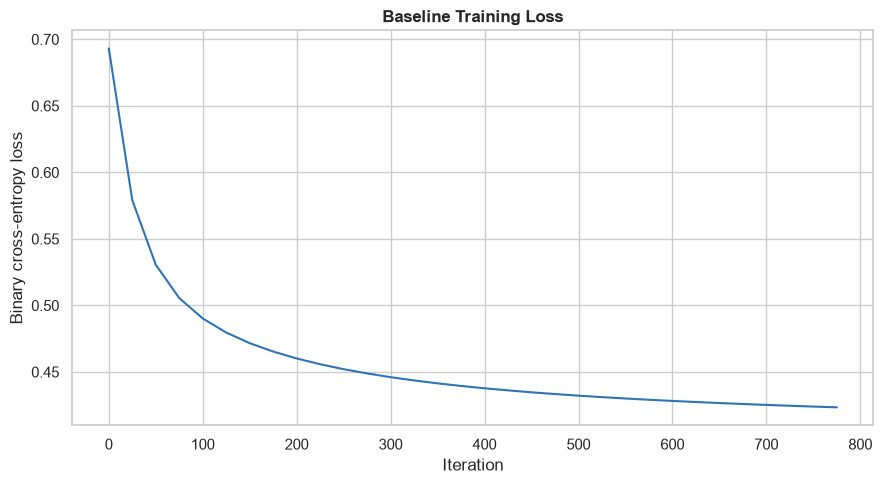

In [40]:
plt.figure(figsize=(9,5)); plt.plot(np.arange(len(baseline.loss))*25,baseline.loss,color=BLUE); plt.xlabel('Iteration'); plt.ylabel('Binary cross-entropy loss'); plt.title('Baseline Training Loss',fontweight='bold'); plt.tight_layout(); plt.show()

The baseline loss was inspected for smooth convergence and instability. It provided the reference model before regularisation and class weighting were introduced.

## Improved Training Loss

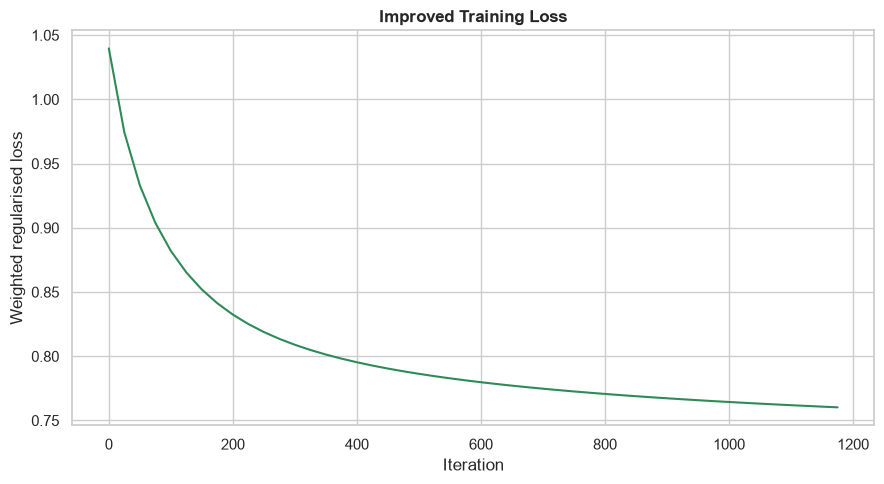

In [41]:
plt.figure(figsize=(9,5)); plt.plot(np.arange(len(improved.loss))*25,improved.loss,color=GREEN); plt.xlabel('Iteration'); plt.ylabel('Weighted regularised loss'); plt.title('Improved Training Loss',fontweight='bold'); plt.tight_layout(); plt.show()

The improved loss used a different objective scale because of weighting and regularisation, so its numeric loss was not compared directly with the baseline loss.

## Validation Performance Comparison

In [42]:
show_table(comparison,'Table 19: Validation Model Comparison',precision=4)

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average precision
Model,,,,,,,
Baseline,0.5000,0.8207,0.7883,0.3860,0.5182,0.8255,0.6787
Improved,0.5400,0.7930,0.5695,0.7038,0.6296,0.8322,0.6833


F1-score was the primary validation selection measure because bestseller status was the minority class. ROC-AUC and average precision were retained as supporting ranking measures.

## Best Validation Thresholds

In [43]:
threshold_scores=pd.DataFrame({'Threshold':thresholds,'Validation F1':threshold_f1}); show_table(threshold_scores.sort_values('Validation F1',ascending=False).head(10),'Table 20: Best Validation Thresholds',precision=4,hide_index=True)

Threshold,Validation F1
0.5400,0.6296
0.5300,0.6288
0.5500,0.6288
0.5700,0.6285
0.5600,0.6270
0.5800,0.6260
0.5200,0.6240
0.5900,0.6228
0.6000,0.6213
0.6300,0.6208


## Threshold-versus-F1 Graph

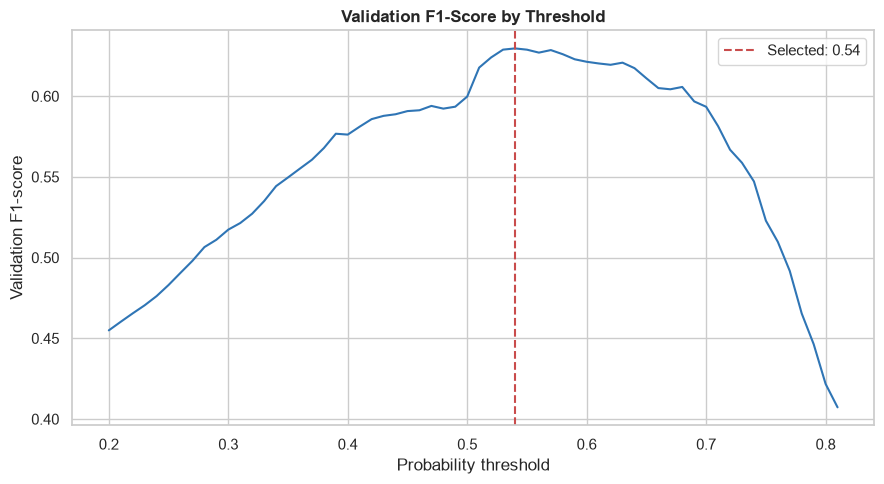

In [44]:
plt.figure(figsize=(9,5)); plt.plot(thresholds,threshold_f1,color=BLUE); plt.axvline(it,color=RED,linestyle='--',label=f'Selected: {it:.2f}'); plt.xlabel('Probability threshold'); plt.ylabel('Validation F1-score'); plt.title('Validation F1-Score by Threshold',fontweight='bold'); plt.legend(); plt.tight_layout(); plt.show()

The improved threshold was selected entirely from validation results. The unseen test set was not inspected during threshold tuning.

## Validation F1 Comparison

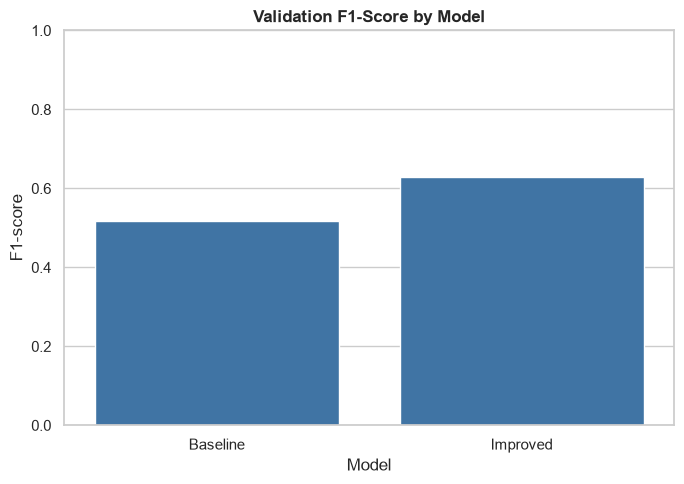

In [45]:
plt.figure(figsize=(7,5)); sns.barplot(data=comparison.reset_index(),x='Model',y='F1-score',color=BLUE); plt.ylim(0,1); plt.title('Validation F1-Score by Model',fontweight='bold'); plt.tight_layout(); plt.show()

## Validation ROC Comparison

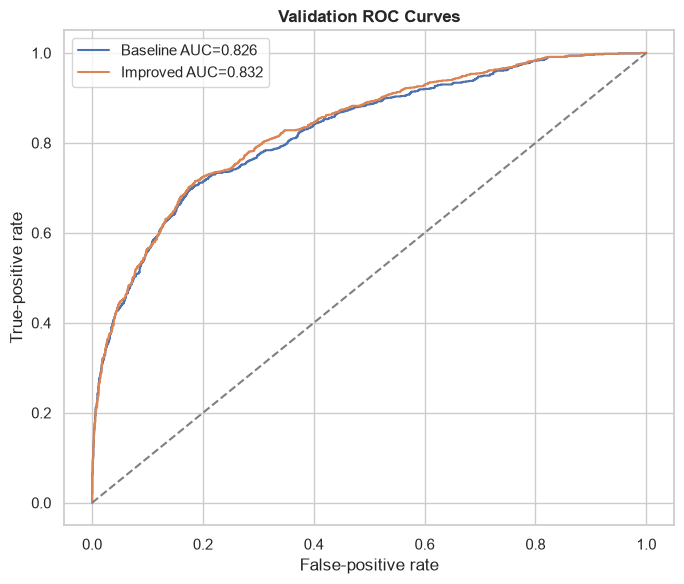

In [46]:
bfpr,btpr,_=roc_curve(y_val,bp); ifpr,itpr,_=roc_curve(y_val,ip); plt.figure(figsize=(7,6)); plt.plot(bfpr,btpr,label=f"Baseline AUC={comparison.loc['Baseline','ROC-AUC']:.3f}"); plt.plot(ifpr,itpr,label=f"Improved AUC={comparison.loc['Improved','ROC-AUC']:.3f}"); plt.plot([0,1],[0,1],'--',color='grey'); plt.xlabel('False-positive rate'); plt.ylabel('True-positive rate'); plt.title('Validation ROC Curves',fontweight='bold'); plt.legend(); plt.tight_layout(); plt.show()

## Final Model Selection and Test Evaluation

In [47]:
if comparison.loc['Improved','F1-score']>comparison.loc['Baseline','F1-score']: final_model,final_name,threshold=improved,'Improved',it
else: final_model,final_name,threshold=baseline,'Baseline',.5
test_prob=final_model.predict_proba(Xte); test_pred=(test_prob>=threshold).astype(int); final_metrics=metrics(y_test,test_prob,threshold,final_name); show_table(pd.DataFrame([final_metrics]).set_index('Model'),'Table 14: Final Test Performance',precision=4)

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average precision
Model,,,,,,,
Improved,0.5400,0.7926,0.5688,0.7051,0.6297,0.8352,0.6680


The final model and threshold were fixed using validation data before test probabilities were generated.

In [48]:
print(f"The {final_name.lower()} model achieved {final_metrics['Accuracy']:.2%} accuracy, {final_metrics['Precision']:.2%} precision, {final_metrics['Recall']:.2%} recall, {final_metrics['F1-score']:.2%} F1 and {final_metrics['ROC-AUC']:.4f} ROC-AUC on the test set.")

The improved model achieved 79.26% accuracy, 56.88% precision, 70.51% recall, 62.97% F1 and 0.8352 ROC-AUC on the test set.


## Classification Report

In [49]:
report=pd.DataFrame(classification_report(y_test,test_pred,target_names=['Non-bestseller','Bestseller'],output_dict=True,zero_division=0)).T; show_table(report,'Table 15: Final Classification Report',precision=4)

,precision,recall,f1-score,support
Non-bestseller,0.8931,0.8218,0.8560,"3,041.0000"
Bestseller,0.5688,0.7051,0.6297,"1,014.0000"
accuracy,0.7926,0.7926,0.7926,0.7926
macro avg,0.7310,0.7634,0.7428,"4,055.0000"
weighted avg,0.8120,0.7926,0.7994,"4,055.0000"


## Confusion Matrix

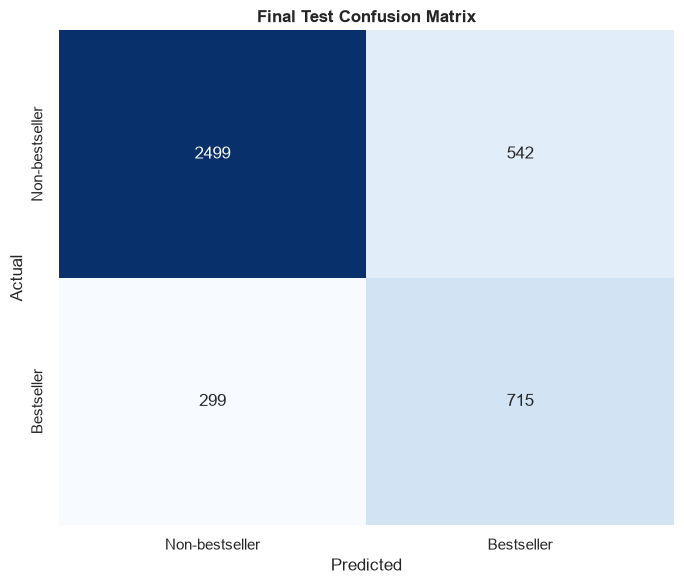

In [50]:
cm=confusion_matrix(y_test,test_pred); plt.figure(figsize=(7,6)); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,xticklabels=['Non-bestseller','Bestseller'],yticklabels=['Non-bestseller','Bestseller']); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Final Test Confusion Matrix',fontweight='bold'); plt.tight_layout(); plt.show()

## Normalised Confusion Matrix

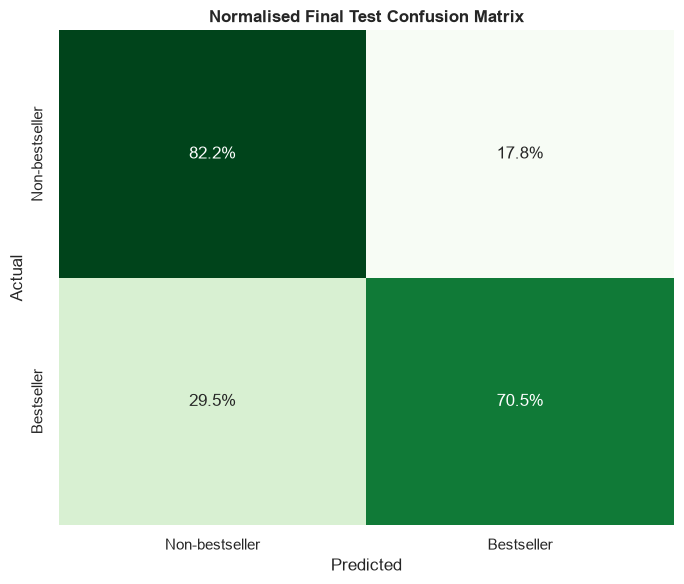

In [51]:
cmn=confusion_matrix(y_test,test_pred,normalize='true'); plt.figure(figsize=(7,6)); sns.heatmap(cmn,annot=True,fmt='.1%',cmap='Greens',cbar=False,xticklabels=['Non-bestseller','Bestseller'],yticklabels=['Non-bestseller','Bestseller']); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Normalised Final Test Confusion Matrix',fontweight='bold'); plt.tight_layout(); plt.show()

In [52]:
print(f'True negatives: {cm[0,0]:,}; false positives: {cm[0,1]:,}; false negatives: {cm[1,0]:,}; true positives: {cm[1,1]:,}.')

True negatives: 2,499; false positives: 542; false negatives: 299; true positives: 715.


## ROC Curve

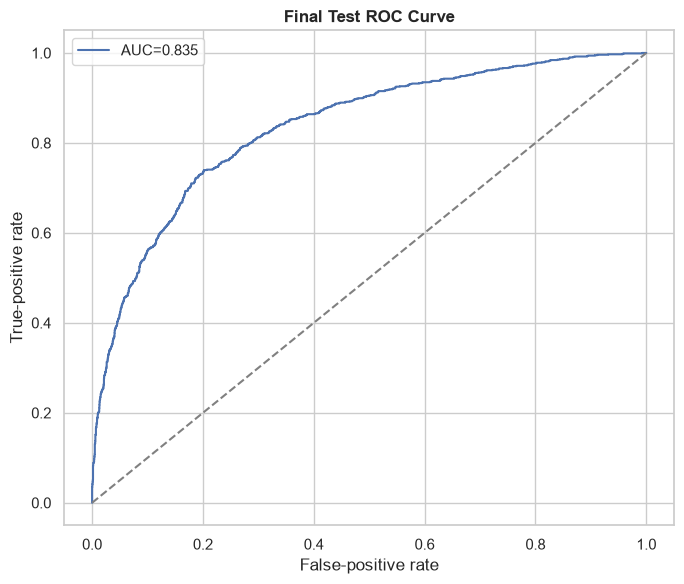

In [53]:
fpr,tpr,_=roc_curve(y_test,test_prob); plt.figure(figsize=(7,6)); plt.plot(fpr,tpr,label=f"AUC={final_metrics['ROC-AUC']:.3f}"); plt.plot([0,1],[0,1],'--',color='grey'); plt.xlabel('False-positive rate'); plt.ylabel('True-positive rate'); plt.title('Final Test ROC Curve',fontweight='bold'); plt.legend(); plt.tight_layout(); plt.show()

## Precision-Recall Curve

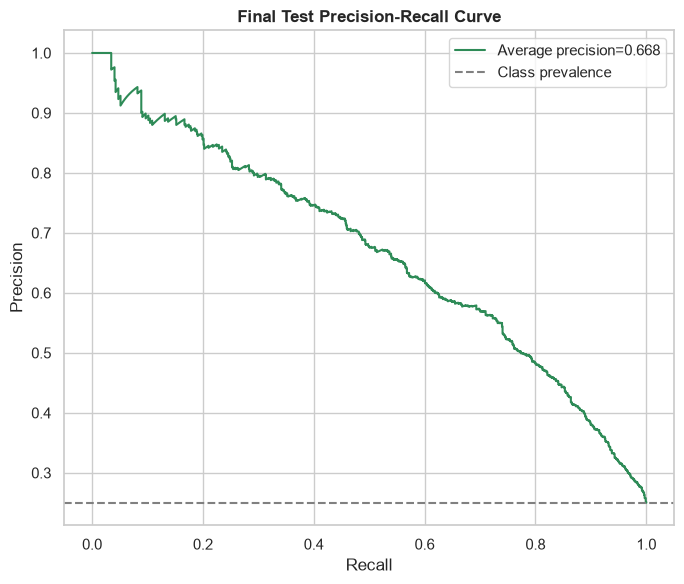

In [54]:
pr,re,_=precision_recall_curve(y_test,test_prob); plt.figure(figsize=(7,6)); plt.plot(re,pr,color=GREEN,label=f"Average precision={final_metrics['Average precision']:.3f}"); plt.axhline(y_test.mean(),color='grey',linestyle='--',label='Class prevalence'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Final Test Precision-Recall Curve',fontweight='bold'); plt.legend(); plt.tight_layout(); plt.show()

## Predicted-Probability Distribution

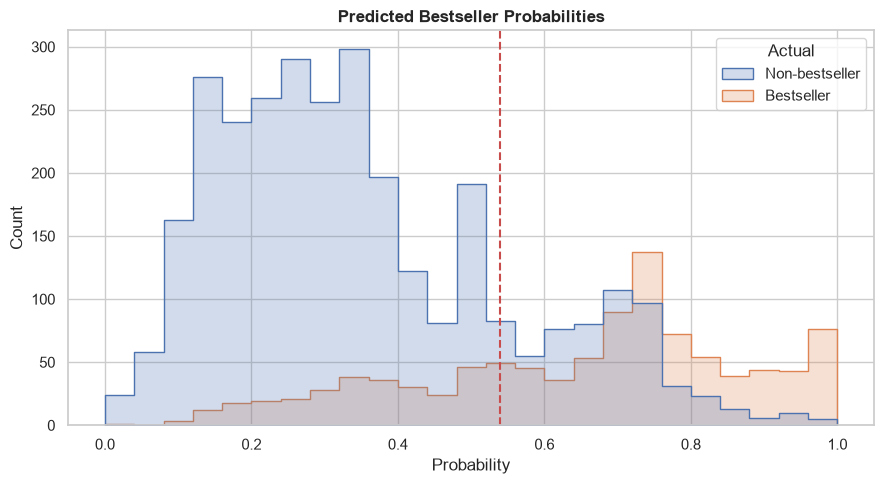

In [55]:
prob_plot=pd.DataFrame({'Probability':test_prob,'Actual':np.where(y_test.to_numpy()==1,'Bestseller','Non-bestseller')}); plt.figure(figsize=(9,5)); sns.histplot(data=prob_plot,x='Probability',hue='Actual',bins=25,element='step',common_norm=False); plt.axvline(threshold,color=RED,linestyle='--'); plt.title('Predicted Bestseller Probabilities',fontweight='bold'); plt.tight_layout(); plt.show()

## Coefficient Interpretation

In [56]:
coef=pd.DataFrame({'Feature':names,'Coefficient':final_model.weights,'Odds ratio':np.exp(final_model.weights)}); coef['Absolute coefficient']=coef.Coefficient.abs(); coef=coef.sort_values('Absolute coefficient',ascending=False); show_table(coef.head(15).set_index('Feature'),'Table 16: Most Influential Coefficients',precision=4)

,Coefficient,Odds ratio,Absolute coefficient
Feature,,,
num__total_reviews,1.7377,5.6842,1.7377
cat__genre_genre fiction,1.0606,2.8881,1.0606
cat__publisher_type_small/medium,-0.5899,0.5544,0.5899
cat__genre_nonfiction,-0.5124,0.5991,0.5124
cat__genre_fiction,0.4327,1.5414,0.4327
num__sale_price,-0.3852,0.6803,0.3852
cat__publisher_type_indie,0.2284,1.2566,0.2284
cat__genre_comics,-0.2012,0.8178,0.2012
cat__seller_Random House LLC,-0.1239,0.8835,0.1239


Positive coefficients increased the estimated bestseller odds relative to a reference group, while negative coefficients reduced them. These were associations and not causal effects.

## Coefficient Graph

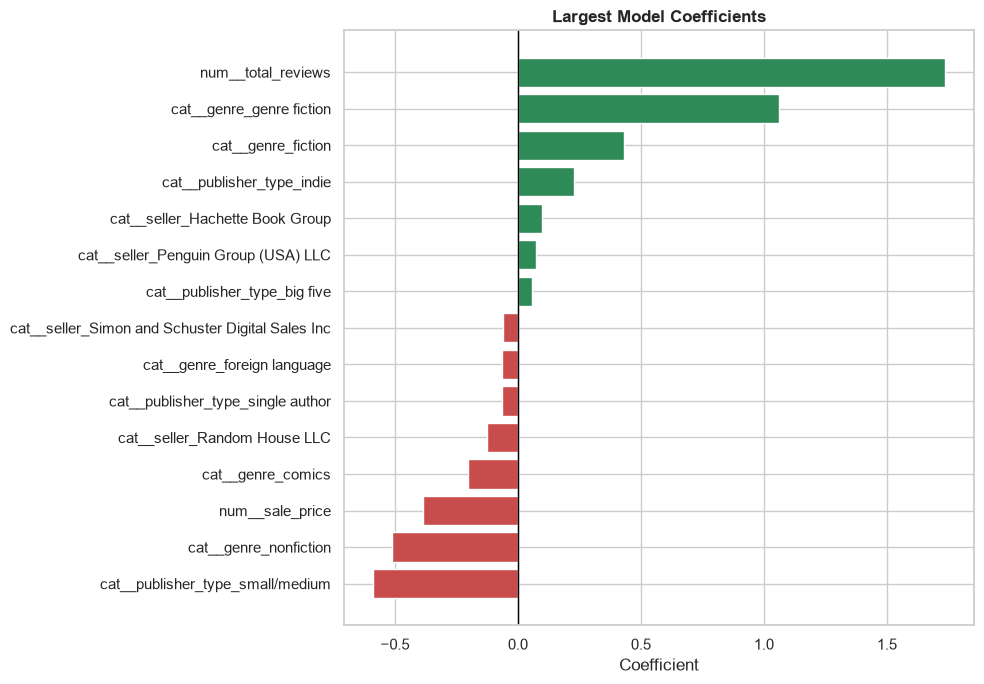

In [57]:
top_coef=coef.head(15).sort_values('Coefficient'); plt.figure(figsize=(10,7)); plt.barh(top_coef.Feature,top_coef.Coefficient,color=[GREEN if x>0 else RED for x in top_coef.Coefficient]); plt.axvline(0,color='black',linewidth=1); plt.xlabel('Coefficient'); plt.title('Largest Model Coefficients',fontweight='bold'); plt.tight_layout(); plt.show()

## Bestseller Screening Demonstration

In [58]:
demo=X_test.copy(); demo['Actual']=np.where(y_test.to_numpy()==1,'Bestseller','Non-bestseller'); demo['Probability']=test_prob; demo['Prediction']=np.where(test_pred==1,'Bestseller','Non-bestseller'); demo['Correct']=np.where(test_pred==y_test.to_numpy(),'Yes','No'); show_table(demo.sort_values('Probability',ascending=False).head(10),'Table 24: Example Screening Results',precision=4,hide_index=True)

average_rating,sale_price,total_reviews,genre,seller,publisher_type,Actual,Probability,Prediction,Correct
4.1400,5.5600,"7,043",fiction,Hachette Book Group,big five,Bestseller,1.0000,Bestseller,Yes
4.7700,6.9900,"6,544",nonfiction,Random House LLC,big five,Bestseller,1.0000,Bestseller,Yes
4.4400,7.9900,"6,353",nonfiction,HarperCollins Christian Publishing,big five,Bestseller,1.0000,Bestseller,Yes
4.5800,7.5000,"4,938",genre fiction,Simon and Schuster Digital Sales Inc,big five,Bestseller,1.0000,Bestseller,Yes
4.4400,4.9900,"4,874",genre fiction,Random House LLC,big five,Bestseller,1.0000,Bestseller,Yes
2.9700,9.8900,"3,914",genre fiction,Penguin Group (USA) LLC,big five,Bestseller,1.0000,Bestseller,Yes
4.2600,6.8300,"3,771",genre fiction,Hachette Book Group,big five,Bestseller,1.0000,Bestseller,Yes
3.8300,6.9900,"3,536",genre fiction,Hachette Book Group,big five,Bestseller,1.0000,Bestseller,Yes
4.4500,4.9900,"3,620",nonfiction,HarperCollins Publishers,big five,Bestseller,1.0000,Bestseller,Yes
4.8400,7.5900,"3,223",children,Random House LLC,big five,Bestseller,1.0000,Bestseller,Yes


The screening table demonstrated how probabilities could prioritise books for commercial review. It did not replace editorial or marketing judgement.

# Limitations and Recommendations
The source contains no title or author, is not time-oriented and defines success only relative to this sample. Reviews and ratings are post-release signals, so deployment before publication would be inappropriate. The press should collect timestamped internal data containing pre-orders, marketing expenditure, distribution, format, author history and an agreed bestseller definition. The model should support commercial review rather than replace editorial judgement.

## Saving Model Components

In [59]:
out=Path('part2_model_outputs'); out.mkdir(exist_ok=True)
with open(out/'preprocessor.pkl','wb') as f: pickle.dump(pre,f)
with open(out/'logistic_regression_from_scratch.pkl','wb') as f: pickle.dump(final_model,f)
with open(out/'metadata.json','w') as f: json.dump({'rank_cutoff':rank_cutoff,'threshold':threshold,'model':final_name,'metrics':{k:(float(v) if isinstance(v,(float,np.floating)) else v) for k,v in final_metrics.items()}},f,indent=2)
print('Model components saved successfully.')

Model components saved successfully.


## Stopping Spark

In [60]:
spark.stop(); print('Spark session stopped successfully.')

Spark session stopped successfully.


# Conclusion
I completed a Spark-based analysis of 27,027 records and trained logistic regression from scratch. The workflow separated target construction, feature preparation, validation selection and final testing. Its results demonstrate a proof of concept for early-market screening, subject to the stated data and deployment limitations.